# RegExplain — E1: Tier 0 and Tier 1

This notebook covers **E1: CNN training and evaluation on Tier 0 and Tier 1**. It trains three models from scratch: two GATA1 CNNs on independently simulated Tier 0 datasets and one CTCF CNN on the supplied Tier 1 K562 dataset.

- **Tier 0 — seeds 565 and 566:** Generate a separate dataset for each seed, following Section 3 of the project PDF. Each dataset contains 10,000 sequences of length 101 bp, with background probabilities of 0.3, 0.2, 0.2, and 0.3 for A, C, G, and T. Half receive 1–3 non-overlapping GATA1 motif copies; the other half remain background sequences. Record the planted motif positions and split each shuffled dataset into 7,000 training, 1,500 validation, and 1,500 test sequences. Check the motif information content and PWM-scan baseline before CNN training.
- **Tier 1 — seed 567:** Load the supplied CTCF/K562 sequences and dinucleotide-shuffled negatives. Preserve the official chromosome-based training, validation, and test splits. Here, the seed controls model initialization and training batch order; it does not regenerate the dataset or change its splits.
- **Shared model and training settings:** All three models use the same CNN architecture: two padded convolutional layers with ReLU and max pooling, followed by a small fully connected classifier. Train each model independently for 10 epochs using Adam, a learning rate of 0.001, and a batch size of 128. Retain the checkpoint with the lowest validation loss. Test data are excluded from training and checkpoint selection.
- **Evaluation and filter interpretation:** Report test AUROC and average precision (AP), and plot calibration curves. Build first-layer sequence logos from strongly activating validation windows. Compare these patterns with the corresponding GATA1 or CTCF reference motif; CTCF comparisons include both strands. Report the number of filters with Pearson correlation r ≥ 0.90 as a descriptive similarity measure, not a formal motif-recovery criterion.
- **Saved outputs:** Save model checkpoints, test predictions, evaluation metrics, validation-loss histories, filter-similarity summaries, and figures. Check that reloaded checkpoints reproduce the original predictions on a test batch.

This notebook covers **E1 only**. ISM, DeepLIFT, and the remaining E2–E4 experiments are separate steps.

## 1. Use the project kernel

GitHub's repository page displays notebooks; **GitHub Codespaces** runs them.

Upload this package's `E1` and `.devcontainer` folders to the repository root. Create a Codespace on that branch and wait for its setup to finish. Open `E1/RegExplain_E1.ipynb`, select **RegExplain (Python 3.12)** as the kernel, and click **Run All**. If needed, use **Select Another Kernel → Jupyter Kernel** to find it, or select the Python environment at `E1/.venv/bin/python`.

The setup script installs the instructor's exact requirements into a separate `.venv` before the notebook starts. It does not install into Colab or a running notebook kernel. The CPU build of the specified PyTorch release is sufficient.

For an existing Codespace, rebuild the container after adding the configuration. See `E1/README.md` for the complete upload and run steps.

In [1]:
# Confirm the project kernel before importing scientific packages.
import sys
assert sys.version_info[:2] == (3, 12), "Select RegExplain (Python 3.12) in the kernel menu."
assert sys.prefix != sys.base_prefix, "Select the E1/.venv/bin/python environment."
print("Python:", sys.version.split()[0])
print("Environment:", sys.prefix)

Python: 3.12.14
Environment: /workspace/scratch/032346eeaa1a/tmp/e1_codespaces/E1/.venv


## 2. Imports and version check
The imported versions must match the course environment. CPU and CUDA builds of the specified PyTorch release are both accepted. Numerical results may vary slightly across hardware.

In [2]:
# Import dependencies and verify the versions loaded into this session.
import json, sys, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import logomaker
from pathlib import Path
from copy import deepcopy
from importlib import import_module
from importlib.metadata import version
from urllib.request import urlretrieve
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import CalibrationDisplay

required = {"torch": "2.14.1", "numpy": "2.4.4", "pandas": "3.0.2",
            "sklearn": "1.8.0", "matplotlib": "3.10.9", "logomaker": "0.8.7"}
for name, expected in required.items():
    actual = import_module(name).__version__.split("+")[0]
    assert actual == expected, f"{name}: loaded {actual}, expected {expected}. Select the RegExplain kernel."
source = "https://raw.githubusercontent.com/yueliyl/RegExplain/4e496fea9460db51f2d0ab355681f53cab5a9cb4/"
root = Path("e1_results")
root.mkdir(exist_ok=True)
urlretrieve(source + "requirements.txt", "requirements.txt")
packages = [line.split("==")[0] for line in Path("requirements.txt").read_text().splitlines() if "==" in line]
versions = "\n".join(f"{name}=={version(name)}" for name in packages)
(root / "versions.txt").write_text(versions)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(versions, "\nDevice:", device)

torch==2.14.1+cpu
captum==0.9.0
dice-ml==0.12
memelite==0.5.0
numpy==2.4.4
pandas==3.0.2
scikit-learn==1.8.0
matplotlib==3.10.9
logomaker==0.8.7
scipy==1.17.1 
Device: cpu


## 3. Tier 0 simulation and motif check
Follow PDF Section 3: 101-bp background sequences, A/C/G/T probabilities 0.3/0.2/0.2/0.3, and 1–3 non-overlapping GATA1 copies in half the sequences. The other half remain background sequences. Record the planted positions for E2.

The matrix is specified by the project; it is not a randomly invented motif. Its information content should be approximately 8.54 bits.

In [3]:
# Define the supplied GATA1 probabilities in A, C, G, T order.
background = np.array([0.3, 0.2, 0.2, 0.3])
motif = np.array([
    [.10, .05, .05, .80], [.03, .03, .91, .03], [.91, .03, .03, .03],
    [.03, .03, .03, .91], [.91, .03, .03, .03], [.88, .04, .04, .04],
    [.05, .05, .85, .05]
])
assert np.allclose(motif.sum(axis=1), 1)
information = np.sum(motif * np.log2(motif / background))
print("GATA1 information (bits):", information)
assert information >= 8

# Generate independent data, labels, and planted-position masks for each seed.
def simulate(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.choice(4, size=(n, 101), p=background).astype(np.int8)
    y = np.zeros(n, dtype=np.float32)
    mask = np.zeros((n, 101), dtype=bool)
    for i in range(n // 2):
        starts = []
        n_copies = rng.integers(1, 4)
        while len(starts) < n_copies:
            s = rng.integers(0, 95)
            if all(abs(s - t) >= 7 for t in starts):
                starts.append(s)
        for s in starts:
            for j in range(7):
                X[i, s + j] = rng.choice(4, p=motif[j])
            mask[i, s:s + 7] = True
        y[i] = 1
    order = rng.permutation(n)
    return X[order], y[order], mask[order]

GATA1 information (bits): 8.54014175214812


## 4. Shared CNN and training
All three models have the same 34,753-parameter CNN. Outputs are logits; sigmoid is used only for prediction. Batch size 128, Adam learning rate 0.001, and 10 epochs are our chosen settings. Select the checkpoint using validation loss only.

In [4]:
# Encode DNA and create reproducible batches.
def make_loader(X, y, shuffle=False, seed=565):
    X = torch.tensor(np.eye(4)[X].transpose(0, 2, 1), dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    return DataLoader(TensorDataset(X, y), batch_size=128, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed))

# Initialize the same padded CNN from scratch.
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
        nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)
    ).to(device)

# Keep the weights with the lowest validation loss, not the final epoch by default.
def train_model(model, train_loader, val_loader):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    best_loss, history = float("inf"), []
    for epoch in range(10):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X.to(device)), y.to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X, y in val_loader:
                val_loss += loss_fn(model(X.to(device)), y.to(device)).item() * len(y)
        val_loss /= len(val_loader.dataset)
        history.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_state = val_loss, deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1}: val_loss={val_loss:.4f}")
    model.load_state_dict(best_state)
    return model, history

## 5. Filter logos and descriptive motif similarity
For each filter, select the strongest complete 15-bp window per validation sequence, then keep up to 100 sequences with the highest positive activations. Padding is excluded.

Compare smoothed base frequencies with the known motif using Pearson correlation, taking the best full-motif alignment inside the 15-bp window. Tier 0 uses the planted forward GATA1 motif; Tier 1 checks both strands of CTCF.

**`r ≥ 0.90` is our descriptive threshold, not a PDF requirement or a statistical significance test.** It measures frequency-profile similarity, not causal recovery of individual nucleotides. Partial or shifted motifs can fall below this threshold. Inactive or undefined filters receive `NaN`. All per-filter values are saved.

In [5]:
# Plot learned logos and quantify similarity to the appropriate reference motif.
def plot_filters(model, loader, X, out, known, bg, reverse=False, report=True):
    model.eval()
    with torch.no_grad():
        a = torch.cat([model[:2](x.to(device)).cpu() for x, _ in loader]).numpy()[:, :, 7:-7]
    refs = [known, known[::-1, ::-1]] if reverse else [known]
    width = len(known)
    best_r = np.full(64, np.nan)
    fig, axes = plt.subplots(8, 8, figsize=(20, 16), layout="constrained")
    for k, ax in enumerate(axes.flat):
        peak = a[:, k].max(axis=1)
        top = np.argsort(peak)[-100:]
        top = top[peak[top] > 0]
        if len(top) == 0:
            ax.set_title(f"Filter {k + 1}: inactive", fontsize=9)
            ax.axis("off")
            continue
        start = a[top, k].argmax(axis=1)
        windows = np.array([X[i, s:s + 15] for i, s in zip(top, start)])
        counts = pd.DataFrame(np.eye(4)[windows].sum(axis=0), columns=list("ACGT"))
        probs = (counts.values + 1) / (counts.values + 1).sum(axis=1, keepdims=True)
        r = [np.corrcoef(probs[o:o + width].ravel(), ref.ravel())[0, 1]
             for ref in refs for o in range(16 - width) if probs[o:o + width].std() > 0]
        best_r[k] = max(r, default=np.nan)
        logo = logomaker.transform_matrix(counts, from_type="counts", to_type="information",
                                          background=bg, pseudocount=1)
        logomaker.Logo(logo, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
        ax.set_title(f"Filter {k + 1}, r={best_r[k]:.2f}", fontsize=9)
        ax.set(xticks=[0, 7, 14], ylim=(0, 2.4))
    fig.supxlabel("Position within the 15-bp window")
    fig.supylabel("Information (bits)")
    fig.savefig(out / "filters.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame({"filter": np.arange(1, 65), "best_r": best_r}).to_csv(out / "filter_similarity.csv", index=False)
    if report:
        print("Filters with descriptive full-motif similarity r >= 0.90:", int((best_r >= 0.9).sum()), "/ 64")
    return int((best_r >= 0.9).sum())

## 6. Shared evaluation and saving
This helper keeps loaders local, preventing a Model 2 loader from being accidentally reused with Model 1. AUPRC is summarized using scikit-learn's average precision (AP).

Save weights, validation losses, aligned predictions, and plots. Verify that a reloaded checkpoint reproduces predictions. Runtime data files are saved for later work but excluded from the shareable results ZIP.

In [6]:
# Train, evaluate, and save one model using the supplied splits.
def run(train, val, test, seed, name, known, bg, reverse=False):
    out = root / name
    out.mkdir(exist_ok=True)
    print("\n" + name)
    train_loader = make_loader(*train, shuffle=True, seed=seed)
    val_loader, test_loader = make_loader(*val), make_loader(*test)
    model, history = train_model(make_model(seed), train_loader, val_loader)
    with torch.no_grad():
        p = torch.cat([model(x.to(device)).sigmoid().cpu() for x, _ in test_loader]).numpy().ravel()
    metrics = {"model": name, "seed": seed, "AUROC": roc_auc_score(test[1], p),
               "AP": average_precision_score(test[1], p), "best_epoch": int(np.argmin(history) + 1)}
    print(metrics)
    torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "seed": seed,
                "architecture": str(model), "base_order": "ACGT", "output": "logits", "padding": True}, out / "model.pt")
    np.savez_compressed(out / "data.npz", X_train=train[0], y_train=train[1], X_val=val[0], y_val=val[1],
                        X_test=test[0], y_test=test[1], p_test=p)
    pd.DataFrame({"y_test": test[1], "p_test": p}).to_csv(out / "test_predictions.csv", index=False)
    pd.DataFrame({"epoch": range(1, 11), "val_loss": history}).to_csv(out / "training.csv", index=False)
    CalibrationDisplay.from_predictions(test[1], p, n_bins=10, name=name)
    plt.title(name + ": calibration")
    plt.savefig(out / "calibration.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    metrics["filters_r_ge_0.90"] = plot_filters(model, val_loader, val[0], out, known, bg, reverse)
    pd.DataFrame([metrics]).to_csv(out / "metrics.csv", index=False)
    check = make_model(seed)
    check.load_state_dict(torch.load(out / "model.pt", map_location=device, weights_only=True)["state_dict"])
    check.eval()
    with torch.no_grad():
        restored = check(next(iter(test_loader))[0].to(device)).sigmoid().cpu().numpy().ravel()
    np.testing.assert_allclose(restored, p[:len(restored)], rtol=1e-5, atol=1e-6)
    print("Checkpoint reload check passed.")
    return model, p, metrics

## 7. Tier 0: two independent datasets and models
Use the same simulation and architecture, changing the seed. The 7,000 / 1,500 / 1,500 split is applied after shuffling the simulated sequences. Check the PWM baseline before training each model.

Seed 565: PWM-scan AUROC = 0.9520

tier0_seed565
Epoch 1: val_loss=0.6913
Epoch 2: val_loss=0.6733
Epoch 3: val_loss=0.4011
Epoch 4: val_loss=0.2718
Epoch 5: val_loss=0.2672
Epoch 6: val_loss=0.2730
Epoch 7: val_loss=0.2677
Epoch 8: val_loss=0.2714
Epoch 9: val_loss=0.2715
Epoch 10: val_loss=0.2790
{'model': 'tier0_seed565', 'seed': 565, 'AUROC': 0.956972077549126, 'AP': 0.9626149100907917, 'best_epoch': 5}


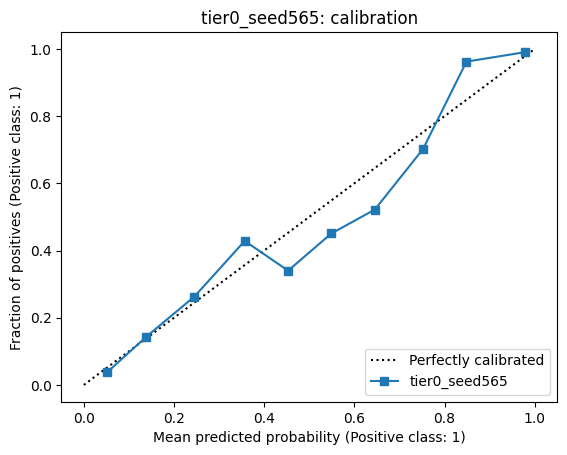

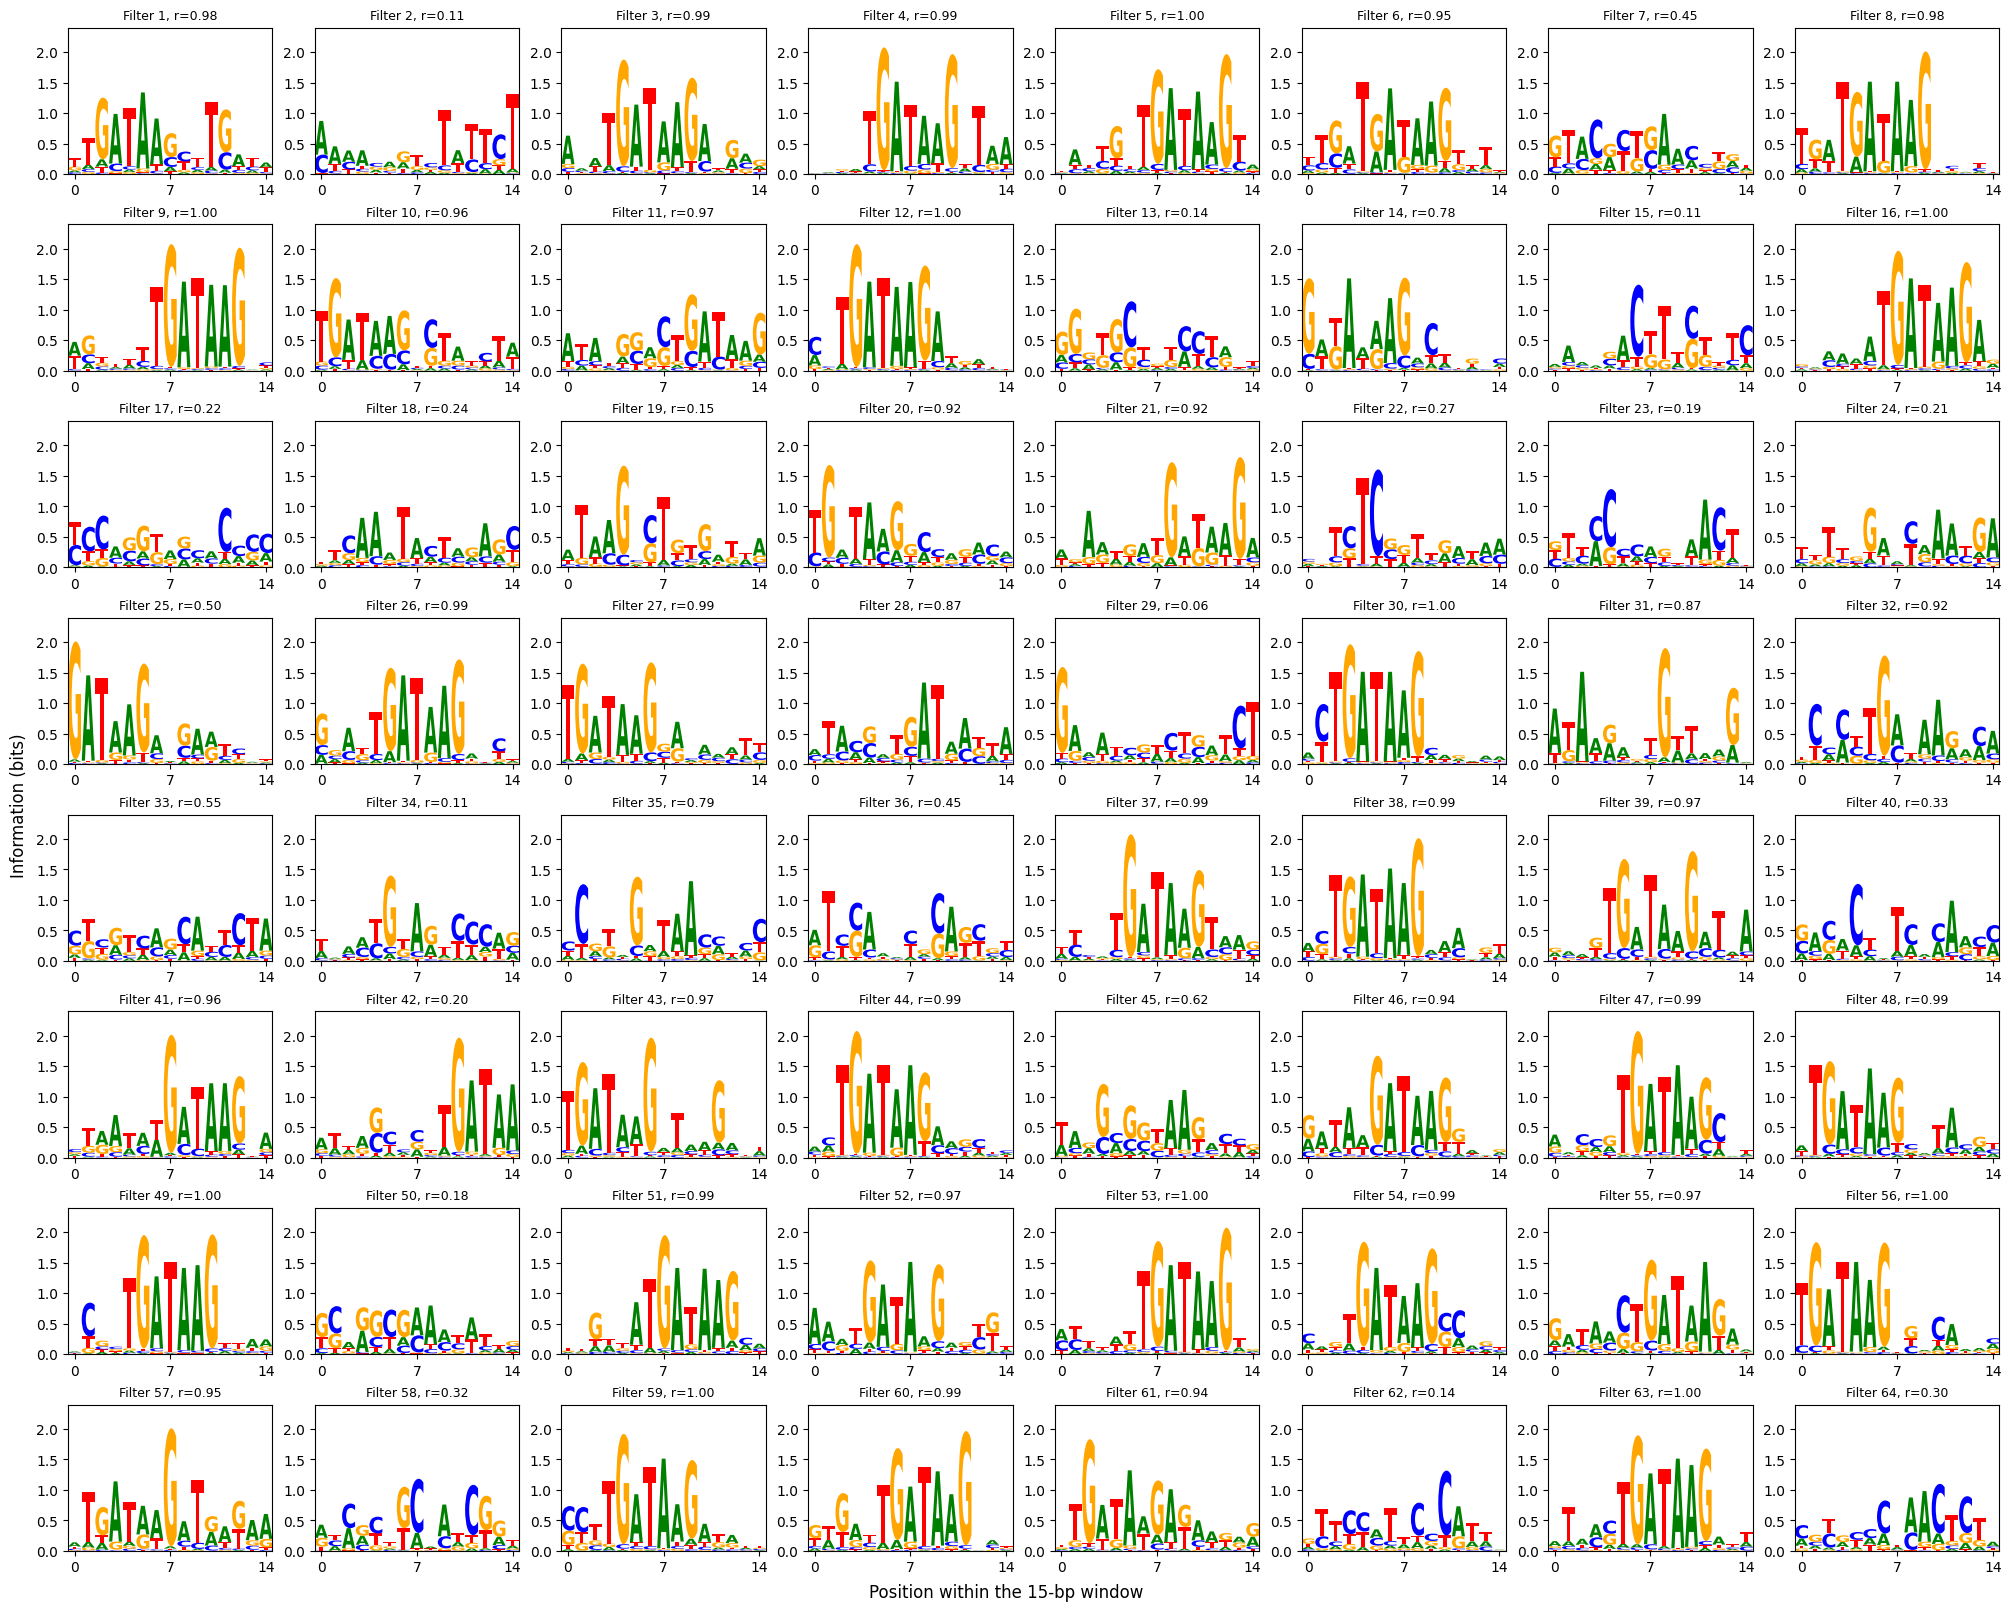

Filters with descriptive full-motif similarity r >= 0.90: 38 / 64
Checkpoint reload check passed.
Seed 566: PWM-scan AUROC = 0.9463

tier0_seed566
Epoch 1: val_loss=0.6417
Epoch 2: val_loss=0.3195
Epoch 3: val_loss=0.2883
Epoch 4: val_loss=0.2859
Epoch 5: val_loss=0.2871
Epoch 6: val_loss=0.2853
Epoch 7: val_loss=0.3071
Epoch 8: val_loss=0.3025
Epoch 9: val_loss=0.2812
Epoch 10: val_loss=0.2791
{'model': 'tier0_seed566', 'seed': 566, 'AUROC': 0.9454209822444798, 'AP': 0.9550799173950275, 'best_epoch': 10}


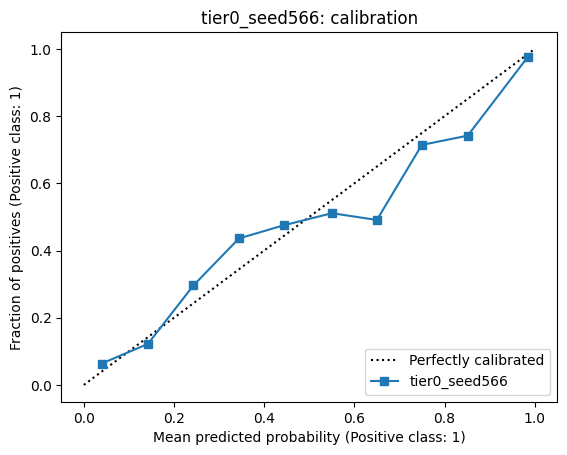

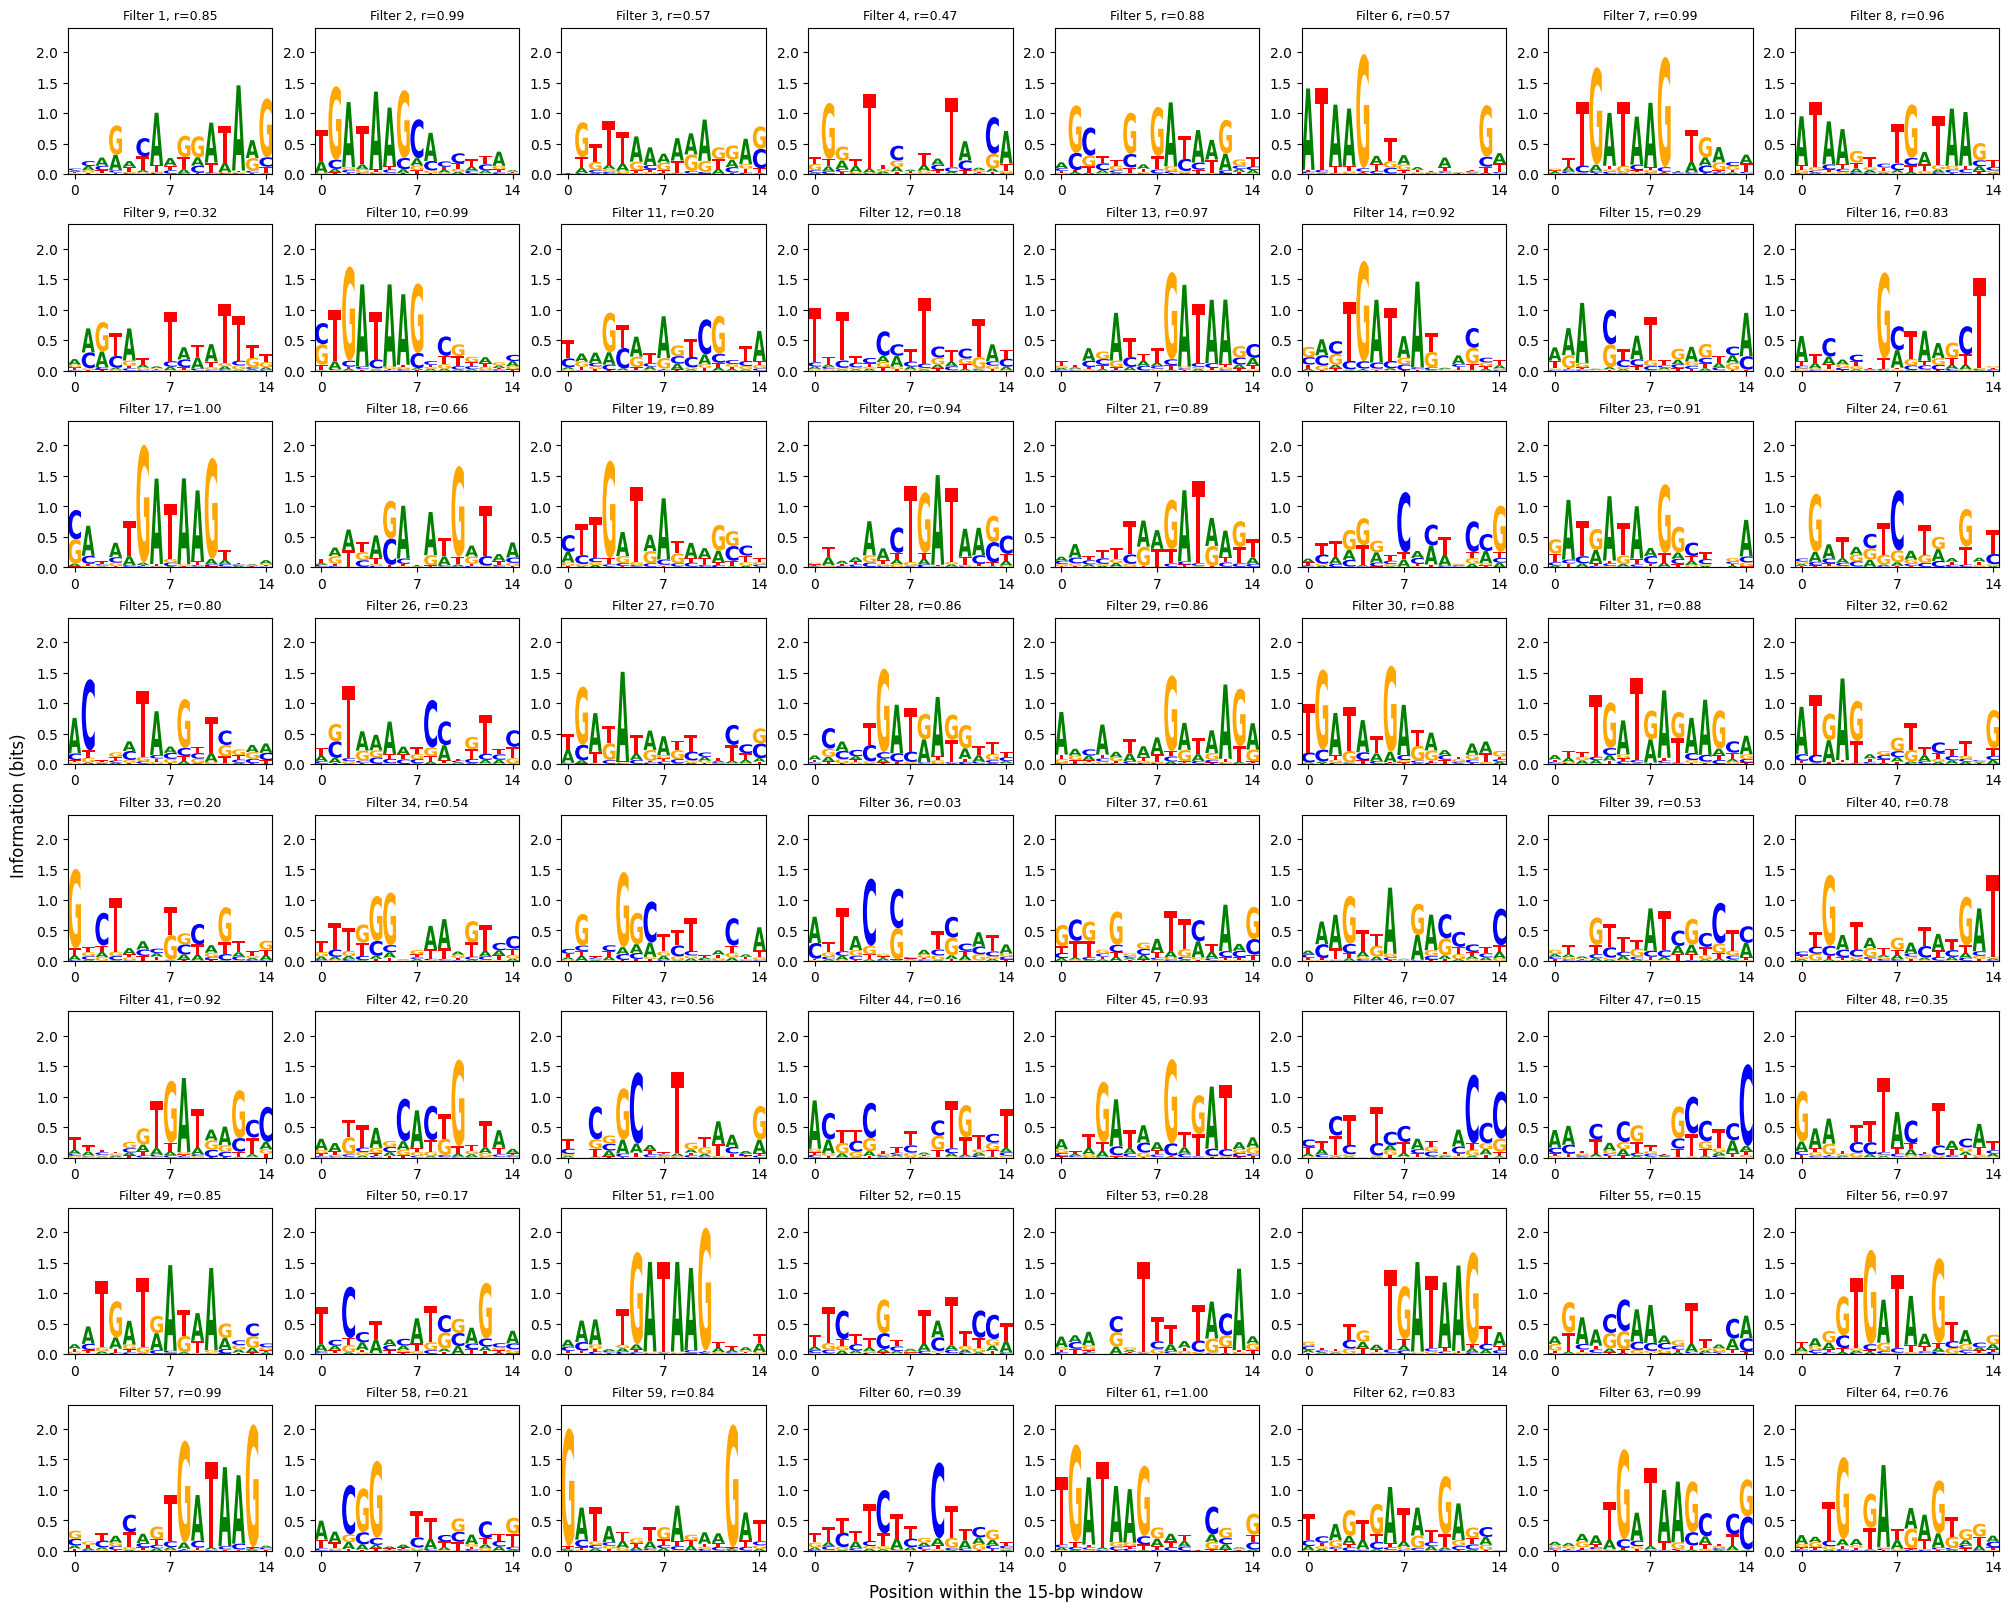

Filters with descriptive full-motif similarity r >= 0.90: 17 / 64
Checkpoint reload check passed.


In [7]:
# Train Tier 0 Models 1 and 2 with independent data and initialization.
runs, results = {}, []
log_odds = np.log2(motif / background)
for seed in (565, 566):
    X, y, mask = simulate(10000, seed)
    scores = np.zeros((len(X), 95))
    for j in range(7):
        scores += log_odds[j, X[:, j:j + 95]]
    pwm_auc = roc_auc_score(y, scores.max(axis=1))
    print(f"Seed {seed}: PWM-scan AUROC = {pwm_auc:.4f}")
    assert pwm_auc > 0.9
    model, p, metrics = run((X[:7000], y[:7000]), (X[7000:8500], y[7000:8500]),
                            (X[8500:], y[8500:]), seed, f"tier0_seed{seed}", motif, background)
    np.save(root / f"tier0_seed{seed}" / "mask_test.npy", mask[8500:])
    metrics["PWM_AUROC"] = pwm_auc
    results.append(metrics)
    runs[seed] = (model, X, y, mask, p)

# Keep Model 1 variables and its test loader aligned for later E2 work.
seed = 565
model, X, y, mask, p = runs[565]
model2, X2, y2, mask2, p2 = runs[566]
X_test, y_test, mask_test = X[8500:], y[8500:], mask[8500:]
test_loader = make_loader(X_test, y_test)

## 8. Tier 1: one CTCF/K562 CNN

Run Steps 8.1–8.12 in order. Each figure and each group of results has its own cell. The model, seed, fixed chromosome splits, and evaluation methods are unchanged. The reference-motif plots show the known motif; the filter-logo figure shows patterns learned by the CNN.

### 8.1 Load Tier 1 data

Download the instructor files and display the sizes of the unchanged chromosome-based splits.

In [8]:
# Download the official Tier 1 files.
data_dir = Path("tier1_data")
data_dir.mkdir(exist_ok=True)

for name in ["tier1_loader.py", "tier1_CTCF_K562.npz",
             "tier1_CTCF_K562.json", "tier1_CTCF_K562.meme"]:
    urlretrieve(source + name, data_dir / name)

# Keep the official chromosome-based splits.
sys.path.insert(0, str(data_dir.resolve()))
from tier1_loader import load_tier1

train1, val1, test1 = load_tier1(
    data_dir / "tier1_CTCF_K562.npz", negatives="dinuc"
)

print("Train:", train1[0].shape, train1[1].shape)
print("Validation:", val1[0].shape, val1[1].shape)
print("Test:", test1[0].shape, test1[1].shape)

Train: (29388, 101) (29388,)
Validation: (3174, 101) (3174,)
Test: (7438, 101) (7438,)


### 8.2 Check GC content

Compare the positive and negative mean GC values recorded in the supplied metadata.

In [9]:
# Check the GC statistics supplied with the dataset.
info = json.loads((data_dir / "tier1_CTCF_K562.json").read_text())

print("Positive mean GC:", info["gc_positive_mean"])
print("Negative mean GC:", info["gc_dinuc_mean"])

assert np.isclose(info["gc_positive_mean"], info["gc_dinuc_mean"])

Positive mean GC: 0.5743945544554456
Negative mean GC: 0.5743945544554456


### 8.3 Prepare the reference motif

Read the known CTCF motif for filter comparison and estimate background frequencies from training sequences. This cell does not train the CNN or display a figure.

In [10]:
# Read the reference motif from the supplied MEME file.
lines = (data_dir / "tier1_CTCF_K562.meme").read_text().splitlines()

for start, line in enumerate(lines):
    if line.startswith("letter-probability matrix:"):
        break

width = int(line.split("w=")[1].split()[0])
ctcf = np.array(
    [line.split() for line in lines[start + 1:start + 1 + width]],
    dtype=float
)
ctcf /= ctcf.sum(axis=1, keepdims=True)

# Estimate background frequencies from training sequences only.
background1 = np.bincount(train1[0].ravel(), minlength=4)
background1 = background1 / background1.sum()

out1 = root / "tier1_seed567"
out1.mkdir(exist_ok=True)

### 8.4 Train the Tier 1 CNN

Initialize the same CNN with seed 567 and train it from scratch. The output is the validation loss for each epoch; the lowest-loss checkpoint is retained.

In [11]:
# Create batches and train a fresh CNN with seed 567.
train_loader1 = make_loader(train1[0], train1[1], shuffle=True, seed=567)
val_loader1 = make_loader(val1[0], val1[1])
test_loader1 = make_loader(test1[0], test1[1])

model_tier1, history1 = train_model(
    make_model(567), train_loader1, val_loader1
)

Epoch 1: val_loss=0.2302
Epoch 2: val_loss=0.1945
Epoch 3: val_loss=0.1707
Epoch 4: val_loss=0.1570
Epoch 5: val_loss=0.1472
Epoch 6: val_loss=0.1437
Epoch 7: val_loss=0.1423
Epoch 8: val_loss=0.1558
Epoch 9: val_loss=0.1367
Epoch 10: val_loss=0.1414


### 8.5 Test metrics

Compute final test predictions and display AUROC and average precision (AP). Test data do not select the checkpoint.

In [12]:
# Evaluate the selected model on the test set.
model_tier1.eval()

with torch.no_grad():
    p1 = torch.cat([
        model_tier1(x.to(device)).sigmoid().cpu()
        for x, _ in test_loader1
    ]).numpy().ravel()

metrics1 = {
    "model": "tier1_seed567",
    "seed": 567,
    "AUROC": roc_auc_score(test1[1], p1),
    "AP": average_precision_score(test1[1], p1),
    "best_epoch": int(np.argmin(history1) + 1)
}

print("Test AUROC:", metrics1["AUROC"])
print("Test AP:", metrics1["AP"])

Test AUROC: 0.9883615100931887
Test AP: 0.9884642277907083


### 8.6 Calibration plot

One figure: test-set calibration in ten equally spaced probability bins.

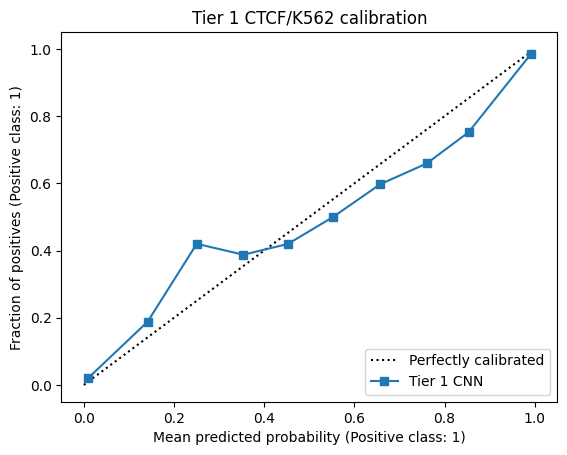

In [13]:
# Plot test-set calibration.
CalibrationDisplay.from_predictions(
    test1[1], p1, n_bins=10, name="Tier 1 CNN"
)
plt.title("Tier 1 CTCF/K562 calibration")
plt.savefig(out1 / "calibration.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### 8.7 First-layer filter logos

One figure: the 64 first-layer filter logos, constructed from strongly activating validation windows. Each title shows similarity to the supplied motif; both motif orientations are compared. The total count is displayed in the next cell.

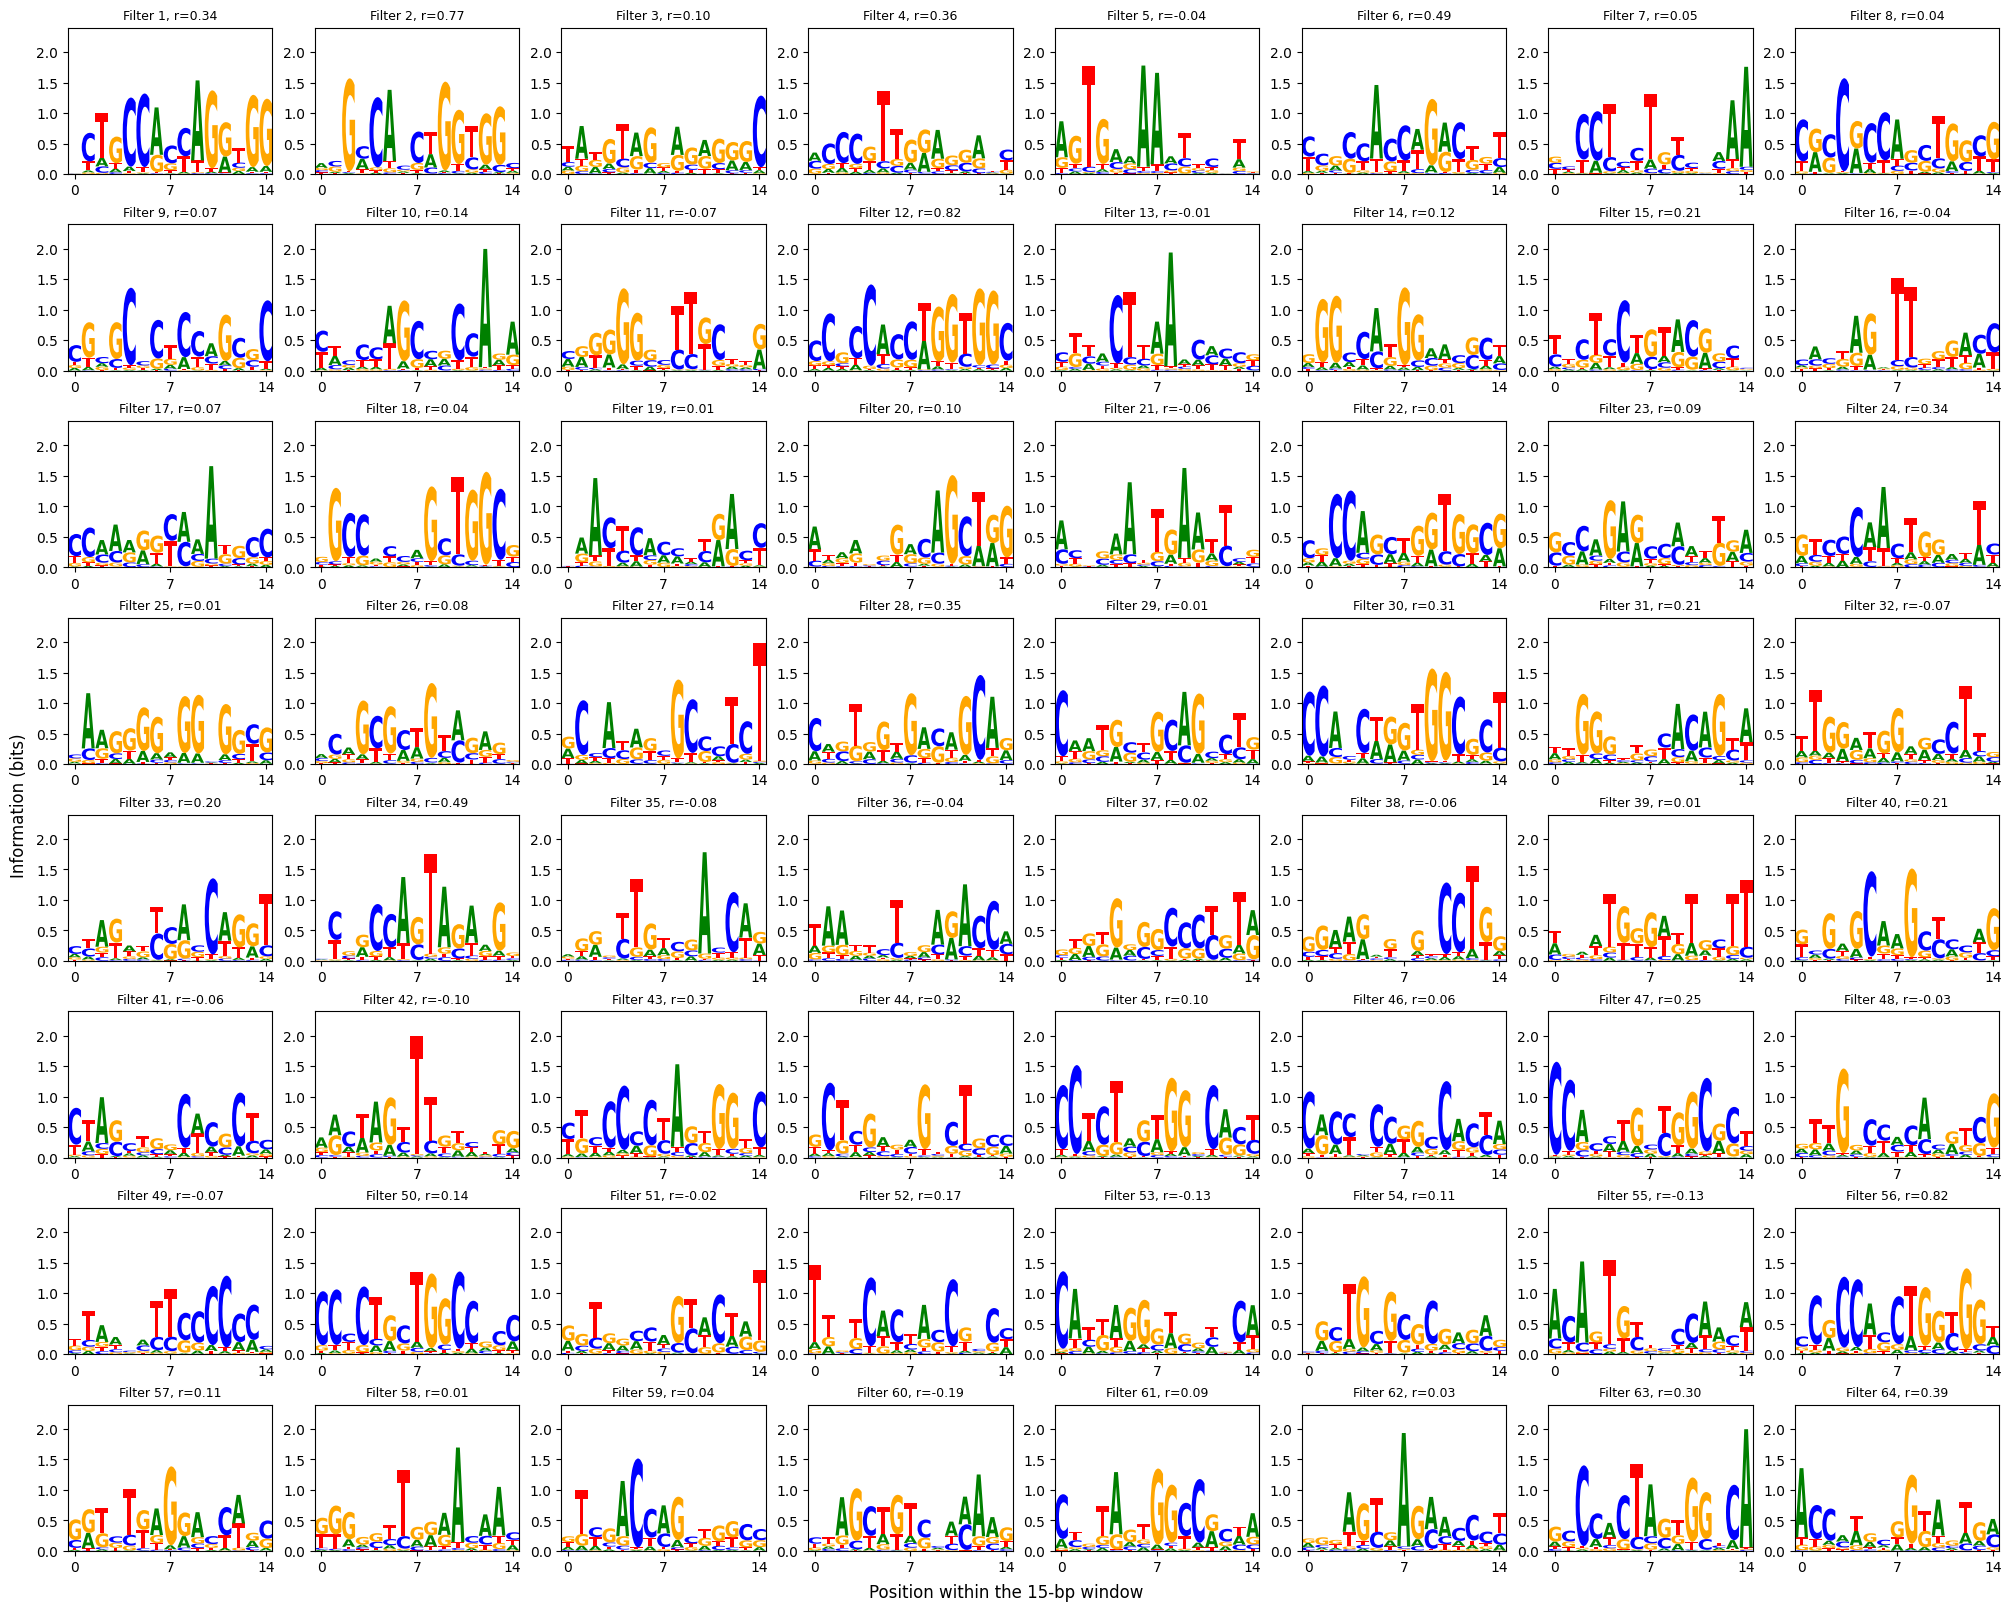

In [14]:
# Plot filters without printing the count in this cell.
n_filters1 = plot_filters(
    model_tier1, val_loader1, val1[0],
    out1, ctcf, background1, reverse=True, report=False
)

### 8.8 Motif-similarity summary

One result: the number of filters passing the descriptive full-motif correlation threshold. This is not a formal recovery or significance test.

In [15]:
# Report the descriptive similarity count separately from the figure.
metrics1["filters_r_ge_0.90"] = n_filters1
print("Filters with full-motif r >= 0.90:", n_filters1, "of 64")

Filters with full-motif r >= 0.90: 0 of 64


### 8.9 CTCF reference: forward

One figure: the supplied reference motif in the forward orientation. This is a known motif, not a learned CNN filter.

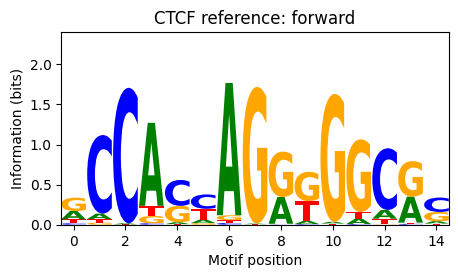

In [16]:
# Plot the supplied reference motif in the forward orientation.
logo1 = logomaker.transform_matrix(
    pd.DataFrame(ctcf, columns=list("ACGT")),
    from_type="probability",
    to_type="information",
    background=background1
)

fig, ax = plt.subplots(figsize=(5, 2.5))
logomaker.Logo(logo1, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
ax.set(title="CTCF reference: forward", xlabel="Motif position",
       ylabel="Information (bits)", ylim=(0, 2.4))
fig.savefig(root / "CTCF_reference_forward.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

### 8.10 CTCF reference: reverse complement

One figure: the same supplied motif on the opposite strand.

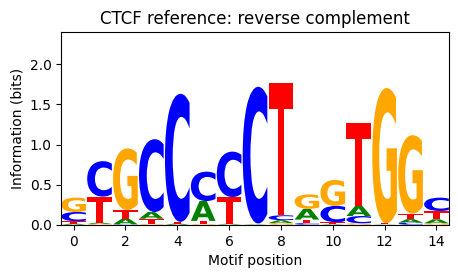

In [17]:
# Reverse the positions and complement the A, C, G, T columns.
logo1 = logomaker.transform_matrix(
    pd.DataFrame(ctcf[::-1, ::-1], columns=list("ACGT")),
    from_type="probability",
    to_type="information",
    background=background1
)

fig, ax = plt.subplots(figsize=(5, 2.5))
logomaker.Logo(logo1, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
ax.set(title="CTCF reference: reverse complement", xlabel="Motif position",
       ylabel="Information (bits)", ylim=(0, 2.4))
fig.savefig(root / "CTCF_reference_reverse.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

### 8.11 Save the Tier 1 model and results

Save the checkpoint, aligned data, test predictions, metrics, and validation-loss history. Keep a single Tier 1 entry in the final summary even if this cell is run again.

In [18]:
# Save the checkpoint and aligned data for later experiments.
torch.save({
    "state_dict": {k: v.cpu() for k, v in model_tier1.state_dict().items()},
    "seed": 567,
    "architecture": str(model_tier1),
    "base_order": "ACGT",
    "output": "logits",
    "padding": True
}, out1 / "model.pt")

np.savez_compressed(
    out1 / "data.npz",
    X_train=train1[0], y_train=train1[1],
    X_val=val1[0], y_val=val1[1],
    X_test=test1[0], y_test=test1[1], p_test=p1
)

pd.DataFrame([metrics1]).to_csv(out1 / "metrics.csv", index=False)
pd.DataFrame({"y_test": test1[1], "p_test": p1}).to_csv(
    out1 / "test_predictions.csv", index=False
)
pd.DataFrame({"epoch": range(1, 11), "val_loss": history1}).to_csv(
    out1 / "training.csv", index=False
)

# Keep one Tier 1 entry if this cell is run again.
results = [r for r in results if r["model"] != "tier1_seed567"]
results.append(metrics1)

print("Files saved to:", out1)

Files saved to: e1_results/tier1_seed567


### 8.12 Reload check

One result: confirm that reloading the saved checkpoint reproduces the predictions on the first test batch.

In [19]:
# Reload the saved weights and compare predictions on one test batch.
check1 = make_model(567)
check1.load_state_dict(
    torch.load(out1 / "model.pt", map_location=device, weights_only=True)["state_dict"]
)
check1.eval()

with torch.no_grad():
    restored1 = check1(
        next(iter(test_loader1))[0].to(device)
    ).sigmoid().cpu().numpy().ravel()

np.testing.assert_allclose(
    restored1, p1[:len(restored1)], rtol=1e-5, atol=1e-6
)
print("Checkpoint reload check passed.")

Checkpoint reload check passed.


## 9. E1 summary
The filter counts below describe full-motif frequency-profile similarity at our chosen threshold. They are not the percentage of causal nucleotides recovered and do not establish statistical significance. The CTCF reference is 15 bp, so a shifted or partial match cannot pass by fitting the whole motif at a different offset inside a 15-bp window. Inspect the logos alongside the counts.

In [20]:
# Save a compact summary and a plain-language motif comparison.
summary = pd.DataFrame(results)
summary.to_csv(root / "summary.csv", index=False)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
notes = [f"{row['model']}: {row['filters_r_ge_0.90']} of 64 filters have best full-motif Pearson r >= 0.90."
         for row in results]
notes.append("This is a descriptive PFM-similarity criterion; partial matches and biological causality require separate interpretation.")
print("\n".join(notes))
(root / "motif_summary.txt").write_text("\n".join(notes))

        model  seed  AUROC     AP  best_epoch  filters_r_ge_0.90  PWM_AUROC
tier0_seed565   565 0.9570 0.9626           5                 38     0.9520
tier0_seed566   566 0.9454 0.9551          10                 17     0.9463
tier1_seed567   567 0.9884 0.9885           9                  0        NaN
tier0_seed565: 38 of 64 filters have best full-motif Pearson r >= 0.90.
tier0_seed566: 17 of 64 filters have best full-motif Pearson r >= 0.90.
tier1_seed567: 0 of 64 filters have best full-motif Pearson r >= 0.90.
This is a descriptive PFM-similarity criterion; partial matches and biological causality require separate interpretation.


## Interpretation of this saved run

The two Tier 0 models reached test AUROC/AP of **0.9570/0.9626** and **0.9454/0.9551**. The specified GATA1 matrix had **8.5401 bits** of information; PWM-scan AUROCs were **0.9520** and **0.9463**. Under the stated descriptive criterion, **38/64** and **17/64** first-layer filters matched the full 7-bp GATA1 frequency profile with r ≥ 0.90.

The Tier 1 model reached test AUROC/AP of **0.9884/0.9885**, while **0/64** filters passed the full-length CTCF comparison at r ≥ 0.90. Its highest full-motif correlation was **0.8247**. The logos include CTCF-like partial patterns, but a partial or shifted pattern is not necessarily a high-correlation match to the complete supplied 15-bp profile. Strong classification therefore does not imply that a single first-layer filter reproduces the complete reference motif; the second convolutional layer can combine partial features.

These counts are not directly comparable across TFs: a 7-bp GATA1 motif has nine full placements inside a 15-bp window, whereas the 15-bp CTCF motif has only one per orientation. The threshold was not changed to improve the Tier 1 count. The counts describe this filter-summary procedure, not biological causality or a percentage of recovered causal nucleotides.

All three checkpoints passed the reload-prediction check. The saved outputs were produced from scratch in a fresh Linux/Python 3.12 environment created with the included setup script. Dependency checks passed. This validates the installation and all notebook code cells locally; the GitHub Codespaces browser session itself was not exercised here. Hardware differences can change the exact numbers slightly.


## 10. Save results

The ZIP includes checkpoints, metrics, prediction tables, validation-loss histories, and figures. It excludes `.npz` and `.npy` data files; those are recreated by the simulation and data-loading cells. In Codespaces, find `E1_results.zip` in the Explorer, right-click it, and choose **Download**. Save the notebook to retain its new outputs. To share changes on GitHub, commit and push the files you want teammates to see; running cells alone does not update the repository.

In [21]:
# Package results without committing datasets or planted-position masks.
with zipfile.ZipFile("E1_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for file in root.rglob("*"):
        if file.is_file() and file.suffix not in (".npz", ".npy", ".pyc"):
            archive.write(file)
print("Results saved to:", Path("E1_results.zip").resolve())

Results saved to: /workspace/scratch/032346eeaa1a/tmp/e1_codespaces/E1/E1_results.zip
